# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.evaluation.metrics import all_time_aggregation_metrics
from src.evaluation.visualization import plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods.IncubationBoostElastic import IncubationBoostElastic
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/other_data/'

## Pick the hourly granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # 1-Hour frequency
FORECAST_HORIZON = '1h'  # 1-Hour forecast horizon
SPIKE_PROMINENCE = 6.5  # Prominence for spike detection, adjusted after EDA
USE_RESIDUAL = True

In [5]:
# Measure loading time
start_time = time.time()

# Load data

train, valid, test = load_dataset(data_dir=data_dir, prefix='od_friedman_hour_wfv', use_numpy=True)

ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 'y_lag_1h', 'y_lag_2h', 'y_lag_3h', 'y_lag_4h', 'y_lag_5h', 'y_lag_6h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 10 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 10 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.01 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 10 splits
Validation data: 10 splits
First train split shape: X=(672, 11), y=(672,)
First valid split shape: X=(672, 11), y=(672,)

Memory usage:
Train: 3.39 MB
Valid: 0.62 MB
Test: 0.37 MB
Total: 4.37 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2000-01-29 07:00:00+01:00 to 2000-02-12 07:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-02-12 07:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2000-02-12 08:00:00+01:00 to 2000-02-26 06:00:00+01:00

-------------------------
Model's memory usage: 0.024628 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6587
	MAE: 1.3123
	MAPE: 9.2403%

Directional Metrics:
	Directional Accuracy: 41.1326%
	First-Diff Correlation: -0.3295

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2000-02-26 07:00:00+01:00 to 2000-03-11 07:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-03-11 07:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2000-03-11 08:00:00+01:00 to 2000-03-25 06:00:00+01:00

-------------------------
Model's memory usage: 0.024490 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.7164
	MAE: 1.3895
	MAPE: 9.4000%

Directional Metrics:
	Directional Accuracy: 35.6185%
	First-Diff Correlation: -0.4034

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2000-09-09 08:00:00+02:00 to 2000-09-23 08:00:00+02:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-09-23 08:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2000-09-23 09:00:00+02:00 to 2000-10-07 07:00:00+02:00

-------------------------
Model's memory usage: 0.024330 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5911
	MAE: 1.2743
	MAPE: 8.9297%

Directional Metrics:
	Directional Accuracy: 34.7243%
	First-Diff Correlation: -0.4276

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2000-10-07 08:00:00+02:00 to 2000-10-21 08:00:00+02:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-10-21 08:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2000-10-21 09:00:00+02:00 to 2000-11-04 06:00:00+01:00

-------------------------
Model's memory usage: 0.024307 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5196
	MAE: 1.2065
	MAPE: 8.6364%

Directional Metrics:
	Directional Accuracy: 36.9598%
	First-Diff Correlation: -0.3974

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5807 ± 0.0694
	MAE: 1.2652 ± 0.0632
	MAPE: 8.7785% ± 0.3722%

	Directional Metrics:
		Directional Accuracy: 36.8703% ± 2.3875%
		First-Diff Correlation: -0.3974 ± 0.0433

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0200 ± 0.0600
		Drop Recall: 0.0200 ± 0.0600
		Drop F1: 0.0200 ± 0.0600

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6017 ± 0.1929
		Spike Recall: 0.6917 ± 0.2556
		Spike F1: 0.6274 ± 0.2024
		Drop Precision: 0.6700 ± 0.2316
		Drop Recall: 0.7550 ± 0.2504
		Drop F1: 0.6939 ± 0.2244
Daily Metrics:
	RMSE: 2.3530 ± 0.3249
	MAE: 1.8765 ± 0.2636
	MAPE: 0.5655% ± 0.0885%

	Directional Metrics:
		Directional Accuracy: 95.0000% ± 5.1010%
		First-Diff Correlation: 0.9974 ± 0.0008

	Immediate Detection (delta=0):
		Spik

#### Validation plots

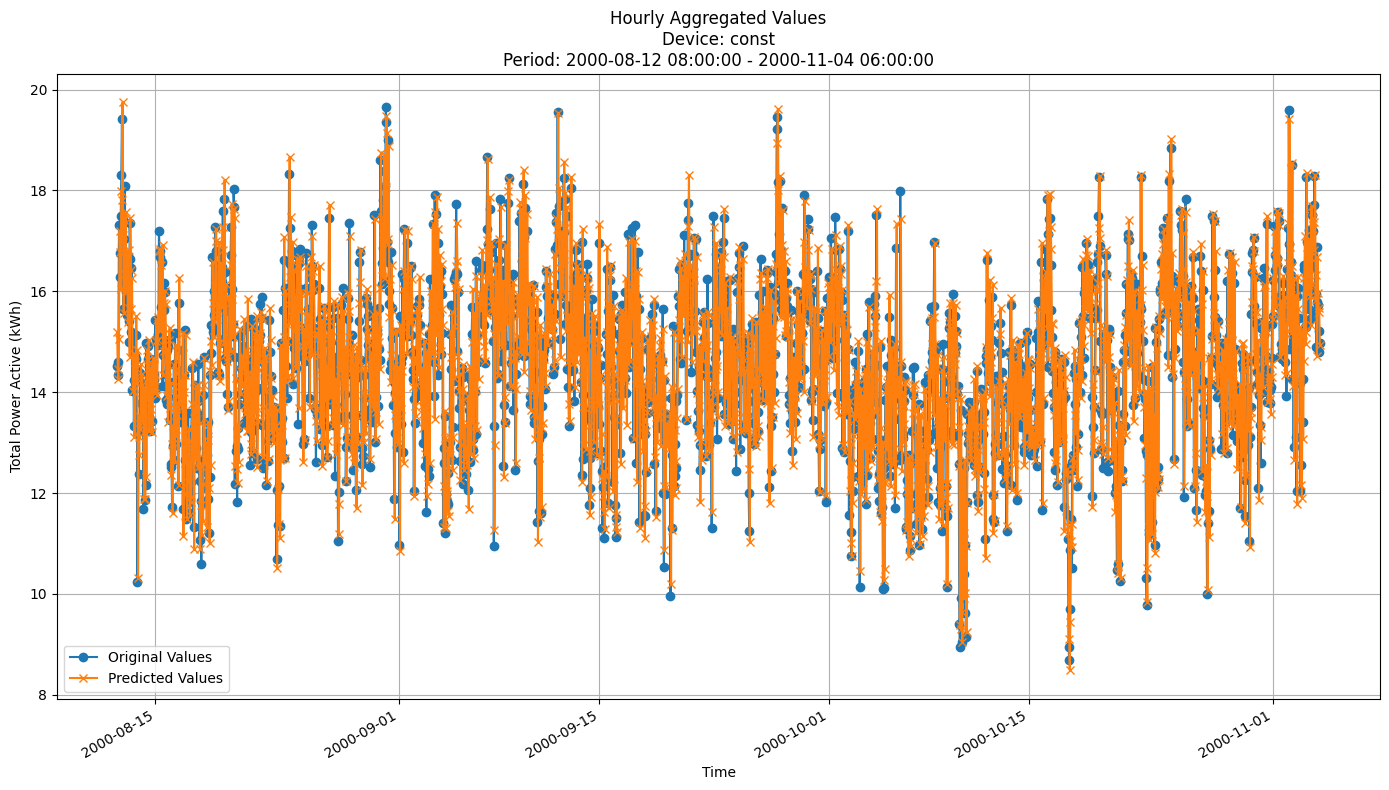


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5451
MAE: 1.2262
MAPE: 8.6416%

Directional Metrics:
Directional Accuracy: 35.6328%
First-Diff Correlation: -0.4239

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': USE_RESIDUAL}

In [12]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00
Model's memory usage: 0.000511 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5169
	MAE: 1.2079
	MAPE: 8.5347%

Directional Metrics:
	Directional Accuracy: 38.7481%
	First-Diff Correlation: -0.3979

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 1.0000
		F1: 0.8000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00
Model's memory usage: 0.000504 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6350
	MAE: 1.3299
	MAPE: 8.9959%

Directional Metrics:
	Directional Accuracy: 36.2146%
	First-Diff Correlation: -0.4446

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00
Model's memory usage: 0.000450 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5634
	MAE: 1.2470
	MAPE: 8.7375%

Directional Metrics:
	Directional Accuracy: 34.1282%
	First-Diff Correlation: -0.4322

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00
Model's memory usage: 0.000443 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5050
	MAE: 1.1936
	MAPE: 8.5502%

Directional Metrics:
	Directional Accuracy: 35.7675%
	First-Diff Correlation: -0.4187

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5323 ± 0.0547
	MAE: 1.2246 ± 0.0544
	MAPE: 8.5008% ± 0.3008%

	Directional Metrics:
		Directional Accuracy: 36.2295% ± 1.9079%
		First-Diff Correlation: -0.4256 ± 0.0360

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9667 ± 0.1000
		Spike Recall: 1.0000 ± 0.0000
		Spike F1: 0.9800 ± 0.0600
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 1.0000 ± 0.0000
		Drop F1: 1.0000 ± 0.0000
Daily Metrics:
	RMSE: 2.1837 ± 0.2779
	MAE: 1.7037 ± 0.2389
	MAPE: 0.5135% ± 0.0725%

	Directional Metrics:
		Directional Accuracy: 94.2857% ± 4.5737%
		First-Diff Correlation: 0.9978 ± 0.0007

	Immediate Detection (delta=0):
		Spik

#### Validation plots

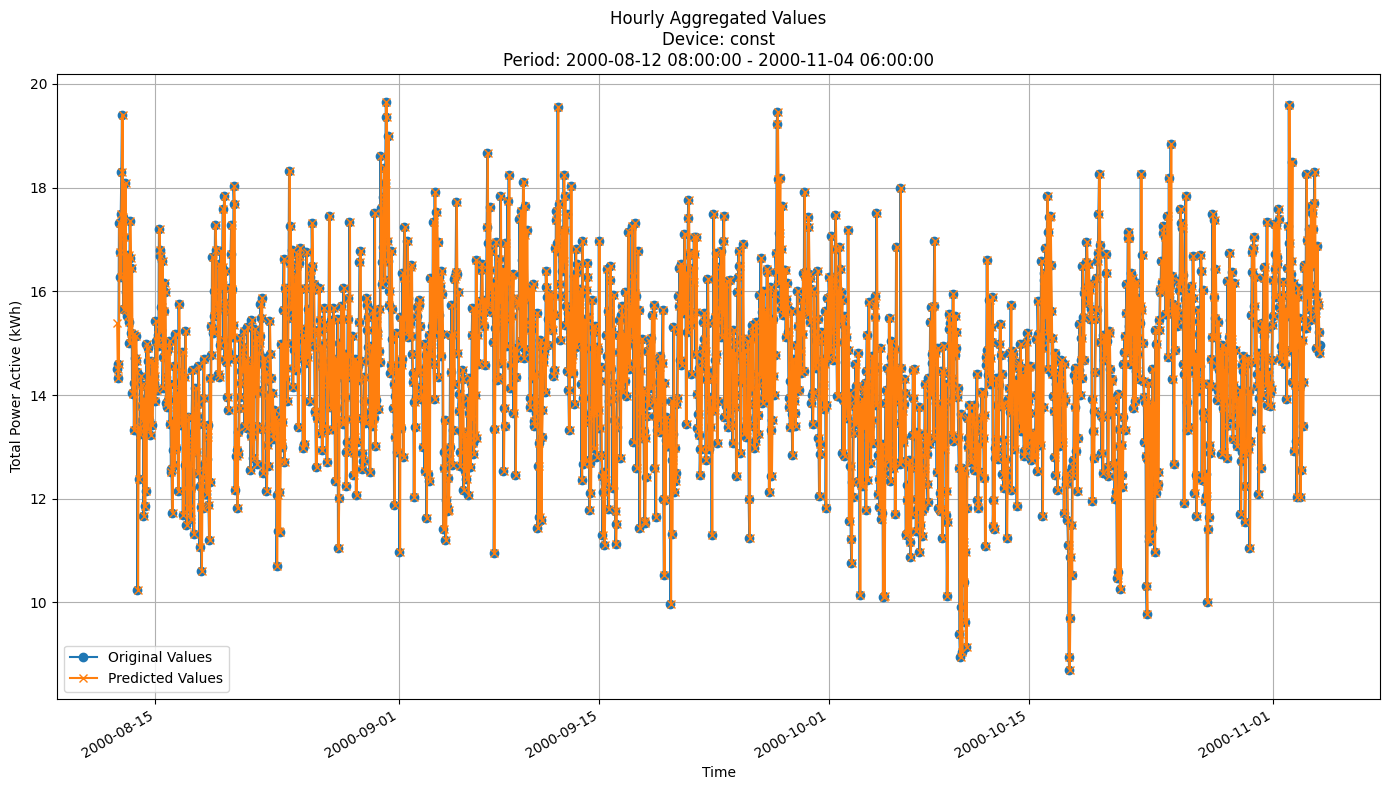


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5236
MAE: 1.2077
MAPE: 8.5128%

Directional Metrics:
Directional Accuracy: 35.1365%
First-Diff Correlation: -0.4338

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = {'n_estimators': 25, 
               'learning_rate': 0.05, 
               'max_depth': 3, 
               'subsample': 1.0, 
               'random_state': 42}

In [16]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00

Time: 0.04 seconds
Predicting for chunk from 2000-01-29 07:00:00+01:00 to 2000-02-12 07:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-02-12 07:00:00+01:00

Time: 0.05 seconds
Predicting for chunk from 2000-02-12 08:00:00+01:00 to 2000-02-26 06:00:00+01:00

-------------------------
Model's memory usage: 0.007675 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5098
	MAE: 1.2077
	MAPE: 8.5275%

Directional Metrics:
	Directional Accuracy: 37.2578%
	First-Diff Correlation: -0.3750

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00

Time: 0.07 seconds
Predicting for chunk from 2000-02-26 07:00:00+01:00 to 2000-03-11 07:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-03-11 07:00:00+01:00

Time: 0.08 seconds
Predicting for chunk from 2000-03-11 08:00:00+01:00 to 2000-03-25 06:00:00+01:00

-------------------------
Model's memory usage: 0.007599 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6454
	MAE: 1.3317
	MAPE: 8.9968%

Directional Metrics:
	Directional Accuracy: 37.5559%
	First-Diff Correlation: -0.4231

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00

Time: 0.29 seconds
Predicting for chunk from 2000-09-09 08:00:00+02:00 to 2000-09-23 08:00:00+02:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-09-23 08:00:00+02:00

Time: 0.31 seconds
Predicting for chunk from 2000-09-23 09:00:00+02:00 to 2000-10-07 07:00:00+02:00

-------------------------
Model's memory usage: 0.007065 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5634
	MAE: 1.2456
	MAPE: 8.7288%

Directional Metrics:
	Directional Accuracy: 34.5753%
	First-Diff Correlation: -0.4262

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.2500
		F1: 0.2857
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00

Time: 0.32 seconds
Predicting for chunk from 2000-10-07 08:00:00+02:00 to 2000-10-21 08:00:00+02:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-10-21 08:00:00+02:00

Time: 0.35 seconds
Predicting for chunk from 2000-10-21 09:00:00+02:00 to 2000-11-04 06:00:00+01:00

-------------------------
Model's memory usage: 0.007004 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5057
	MAE: 1.1920
	MAPE: 8.5464%

Directional Metrics:
	Directional Accuracy: 36.6617%
	First-Diff Correlation: -0.4133

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5218 ± 0.0155
	MAE: 1.2136 ± 0.0145
	MAPE: 8.4751% ± 0.0624%

	Directional Metrics:
		Directional Accuracy: 38.1022% ± 1.1678%
		First-Diff Correlation: -0.3748 ± 0.0368

	Immediate Detection (delta=0):
		Spike Precision: 0.0146 ± 0.0182
		Spike Recall: 0.0142 ± 0.0176
		Spike F1: 0.0144 ± 0.0179
		Drop Precision: 0.0558 ± 0.0433
		Drop Recall: 0.0569 ± 0.0440
		Drop F1: 0.0563 ± 0.0435

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8585 ± 0.1982
		Spike Recall: 0.8966 ± 0.1424
		Spike F1: 0.8746 ± 0.1730
		Drop Precision: 0.9070 ± 0.1407
		Drop Recall: 0.9031 ± 0.1924
		Drop F1: 0.9026 ± 0.1691
Daily Metrics:
	RMSE: 2.5827 ± 0.1745
	MAE: 2.0628 ± 0.1513
	MAPE: 0.6098% ± 0.0716%

	Directional Metrics:
		Directional Accuracy: 95.3420% ± 1.4235%
		First-Diff Correlation: 0.9938 ± 0.0012

	Immediate Detection (delta=0):
		Spik

#### Training plots

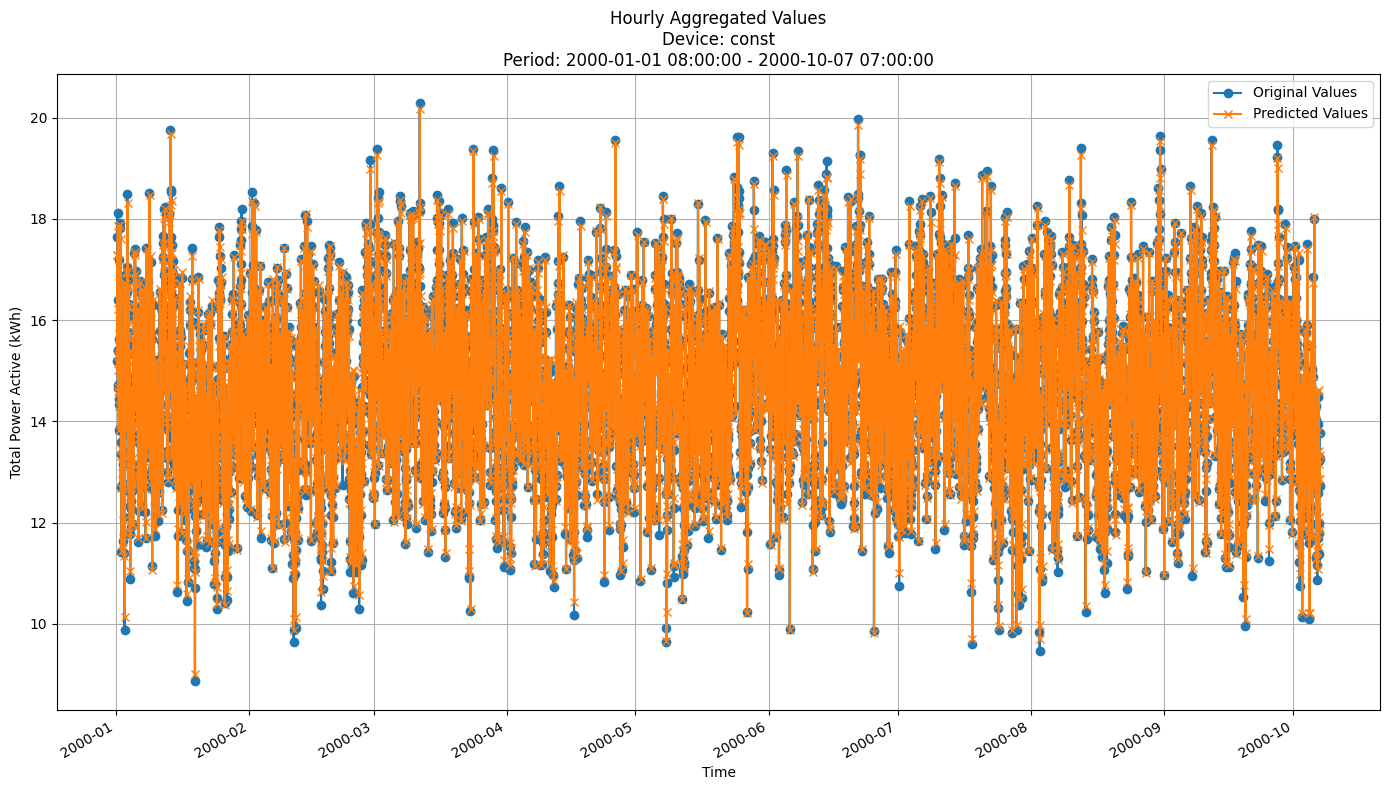


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5278
MAE: 1.2185
MAPE: 8.4601%

Directional Metrics:
Directional Accuracy: 36.7967%
First-Diff Correlation: -0.4077

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

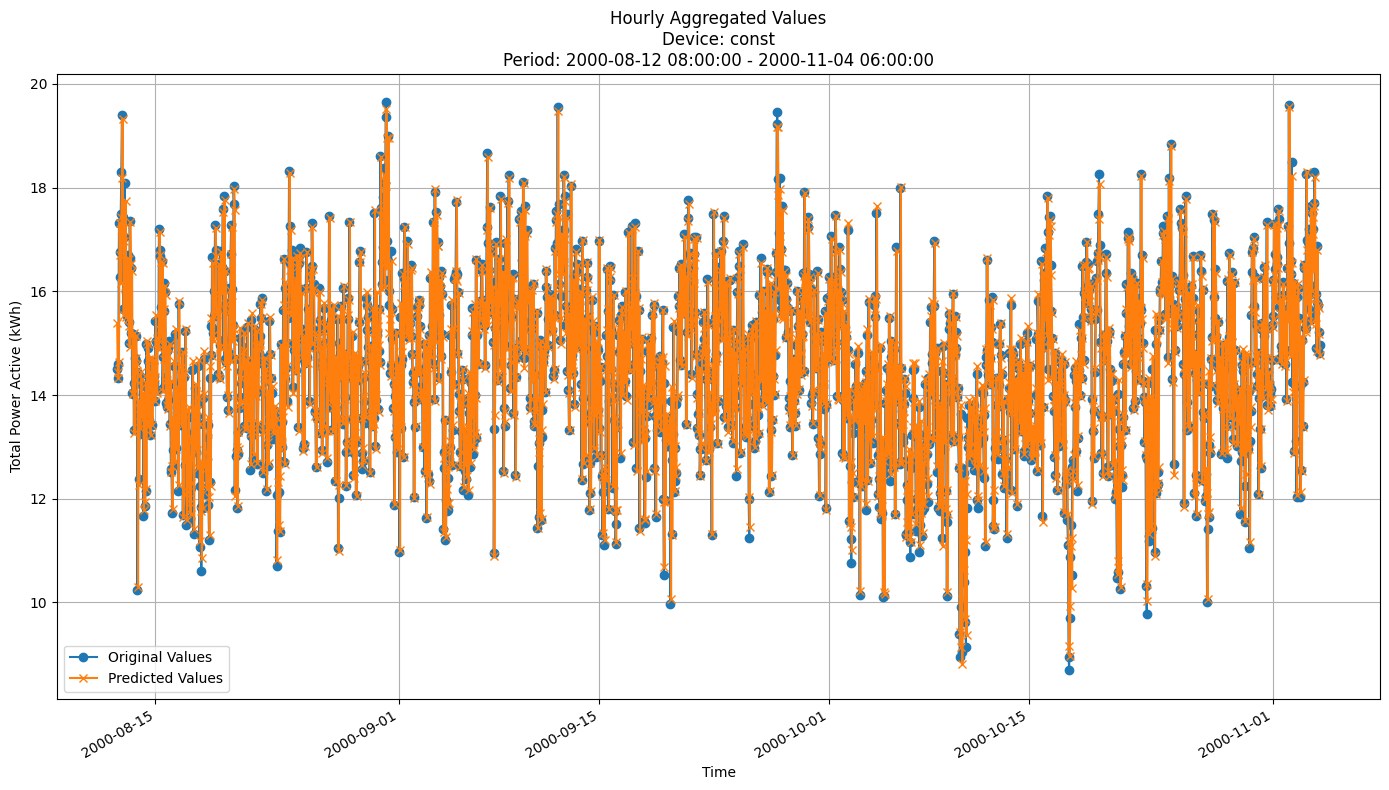


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5240
MAE: 1.2068
MAPE: 8.5099%

Directional Metrics:
Directional Accuracy: 35.6824%
First-Diff Correlation: -0.4271

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {'n_estimators': 100, 
             'max_depth': 3, 
             'max_features': 0.3, 
             'random_state': 42, 
             'n_jobs': -1}

In [21]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2000-01-29 07:00:00+01:00 to 2000-02-12 07:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-02-12 07:00:00+01:00

Time: 0.11 seconds
Predicting for chunk from 2000-02-12 08:00:00+01:00 to 2000-02-26 06:00:00+01:00

-------------------------
Model's memory usage: 0.042099 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5082
	MAE: 1.2074
	MAPE: 8.5341%

Directional Metrics:
	Directional Accuracy: 38.4501%
	First-Diff Correlation: -0.3831

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.5000
		Recall: 0.5000
		F1: 0.5000

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00

Time: 0.10 seconds
Predicting for chunk from 2000-02-26 07:00:00+01:00 to 2000-03-11 07:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-03-11 07:00:00+01:00

Time: 0.10 seconds
Predicting for chunk from 2000-03-11 08:00:00+01:00 to 2000-03-25 06:00:00+01:00

-------------------------
Model's memory usage: 0.042091 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6397
	MAE: 1.3276
	MAPE: 8.9726%

Directional Metrics:
	Directional Accuracy: 37.7049%
	First-Diff Correlation: -0.4323

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00

Time: 0.12 seconds
Predicting for chunk from 2000-09-09 08:00:00+02:00 to 2000-09-23 08:00:00+02:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-09-23 08:00:00+02:00

Time: 0.12 seconds
Predicting for chunk from 2000-09-23 09:00:00+02:00 to 2000-10-07 07:00:00+02:00

-------------------------
Model's memory usage: 0.042091 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5613
	MAE: 1.2443
	MAPE: 8.7204%

Directional Metrics:
	Directional Accuracy: 34.2772%
	First-Diff Correlation: -0.4262

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00

Time: 0.12 seconds
Predicting for chunk from 2000-10-07 08:00:00+02:00 to 2000-10-21 08:00:00+02:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-10-21 08:00:00+02:00

Time: 0.12 seconds
Predicting for chunk from 2000-10-21 09:00:00+02:00 to 2000-11-04 06:00:00+01:00

-------------------------
Model's memory usage: 0.042091 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5011
	MAE: 1.1905
	MAPE: 8.5375%

Directional Metrics:
	Directional Accuracy: 35.6185%
	First-Diff Correlation: -0.4139

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5322 ± 0.0114
	MAE: 1.2216 ± 0.0116
	MAPE: 8.5356% ± 0.0835%

	Directional Metrics:
		Directional Accuracy: 37.8419% ± 1.2354%
		First-Diff Correlation: -0.3862 ± 0.0307

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0292 ± 0.0507
		Drop Recall: 0.0291 ± 0.0507
		Drop F1: 0.0292 ± 0.0507

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8921 ± 0.1957
		Spike Recall: 0.9078 ± 0.1450
		Spike F1: 0.8975 ± 0.1729
		Drop Precision: 0.9408 ± 0.1005
		Drop Recall: 0.9395 ± 0.0954
		Drop F1: 0.9395 ± 0.0945
Daily Metrics:
	RMSE: 2.6198 ± 0.1637
	MAE: 2.0773 ± 0.1216
	MAPE: 0.6154% ± 0.0634%

	Directional Metrics:
		Directional Accuracy: 95.2973% ± 1.4652%
		First-Diff Correlation: 0.9942 ± 0.0012

	Immediate Detection (delta=0):
		Spik

#### Training plots
Plot only the last period of predictions

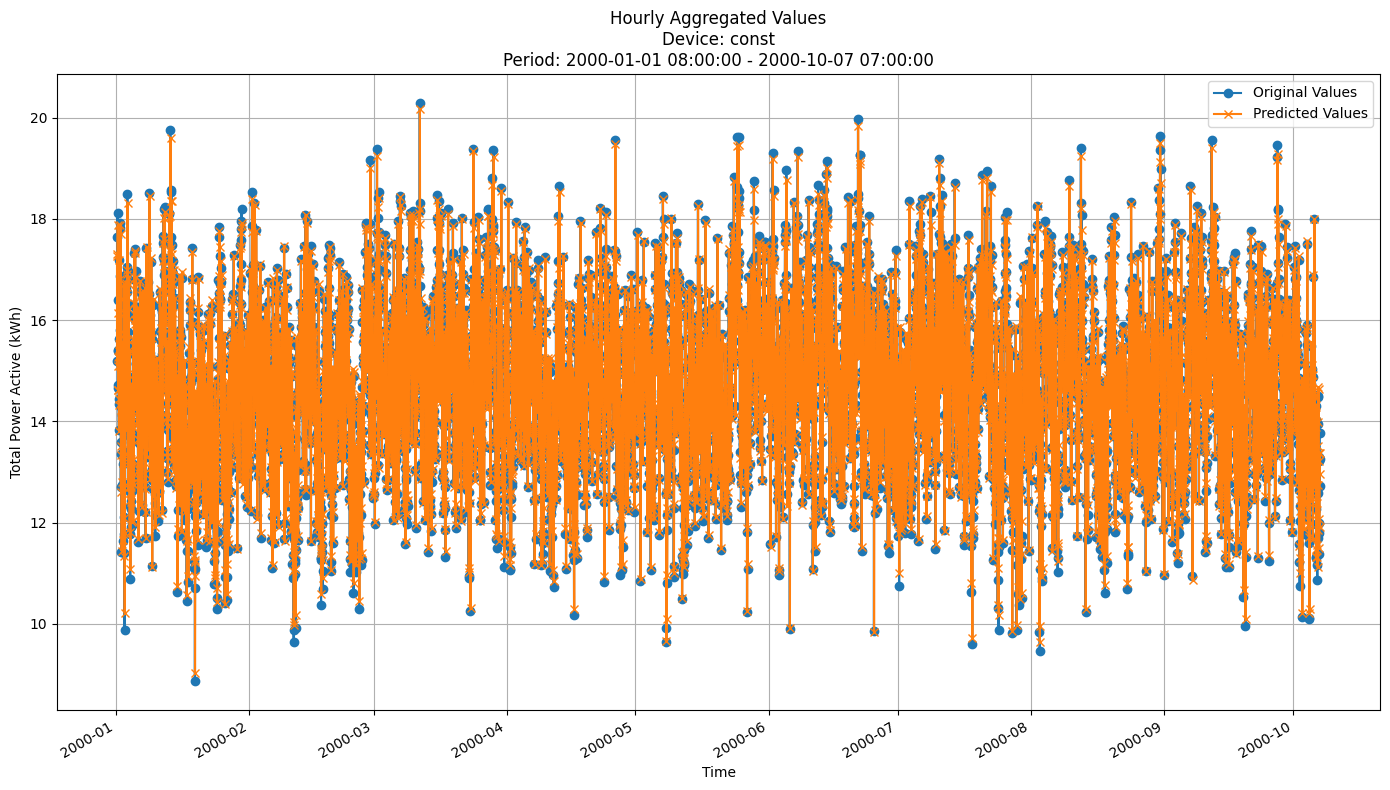


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5312
MAE: 1.2214
MAPE: 8.4812%

Directional Metrics:
Directional Accuracy: 36.6925%
First-Diff Correlation: -0.4121

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

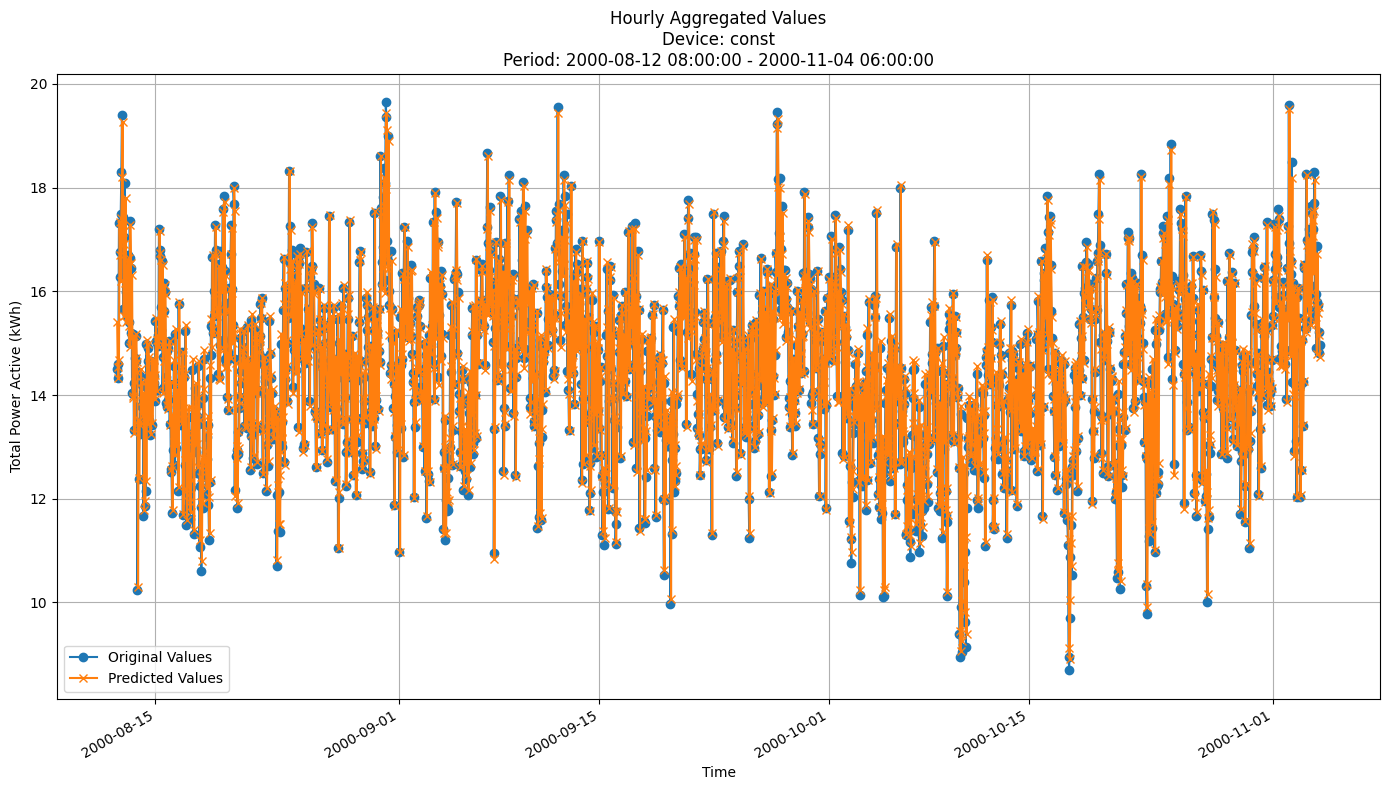


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5212
MAE: 1.2053
MAPE: 8.5009%

Directional Metrics:
Directional Accuracy: 35.0868%
First-Diff Correlation: -0.4284

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [24]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {'max_depth': 3, 
               'grace_period': 96, 
               'tau': 0.01, 
               'delta': 0.01}


In [26]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00
Model's memory usage: 0.171104 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5263
	MAE: 1.2233
	MAPE: 8.6571%

Directional Metrics:
	Directional Accuracy: 39.4933%
	First-Diff Correlation: -0.3792

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.5000
		Recall: 0.5000
		F1: 0.5000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 1.0000
		F1: 0.8000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00
Model's memory usage: 0.176247 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6356
	MAE: 1.3219
	MAPE: 8.9330%

Directional Metrics:
	Directional Accuracy: 37.1088%
	First-Diff Correlation: -0.4283

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00
Model's memory usage: 0.137207 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5620
	MAE: 1.2423
	MAPE: 8.7022%

Directional Metrics:
	Directional Accuracy: 35.4694%
	First-Diff Correlation: -0.4205

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.6667
		Recall: 0.6667
		F1: 0.6667
--------------------------------------------------
Dai

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00
Model's memory usage: 0.165512 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5050
	MAE: 1.1944
	MAPE: 8.5676%

Directional Metrics:
	Directional Accuracy: 36.8107%
	First-Diff Correlation: -0.4130

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 1.0000
		F1: 0.8571
	Drops:
		Precision: 0.6000
		Recall: 0.7500
		F1: 0.6667
--------------------------------------------------
Dai

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5525 ± 0.0166
	MAE: 1.2360 ± 0.0118
	MAPE: 8.6363% ± 0.1435%

	Directional Metrics:
		Directional Accuracy: 37.6792% ± 0.8618%
		First-Diff Correlation: -0.3916 ± 0.0245

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0351 ± 0.0416
		Drop Recall: 0.0383 ± 0.0472
		Drop F1: 0.0366 ± 0.0443

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8210 ± 0.1835
		Spike Recall: 0.8977 ± 0.1408
		Spike F1: 0.8545 ± 0.1620
		Drop Precision: 0.8335 ± 0.1339
		Drop Recall: 0.8927 ± 0.0984
		Drop F1: 0.8604 ± 0.1156
Daily Metrics:
	RMSE: 2.6927 ± 0.2500
	MAE: 2.1348 ± 0.1877
	MAPE: 0.6336% ± 0.0892%

	Directional Metrics:
		Directional Accuracy: 95.1708% ± 0.9570%
		First-Diff Correlation: 0.9937 ± 0.0011

	Immediate Detection (delta=0):
		Spik

#### Training plots
Plot only the last period of predictions

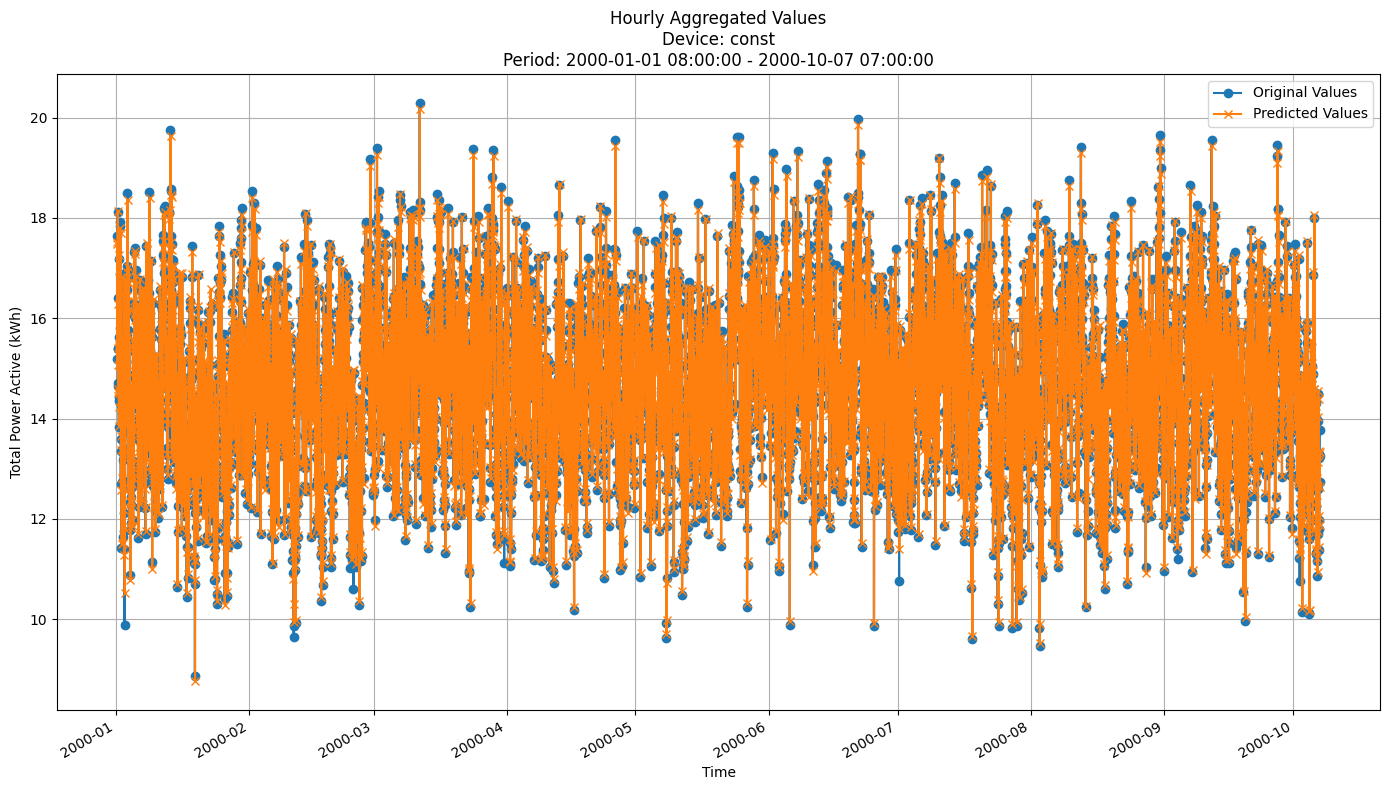


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5389
MAE: 1.2276
MAPE: 8.5222%

Directional Metrics:
Directional Accuracy: 36.7222%
First-Diff Correlation: -0.4114

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

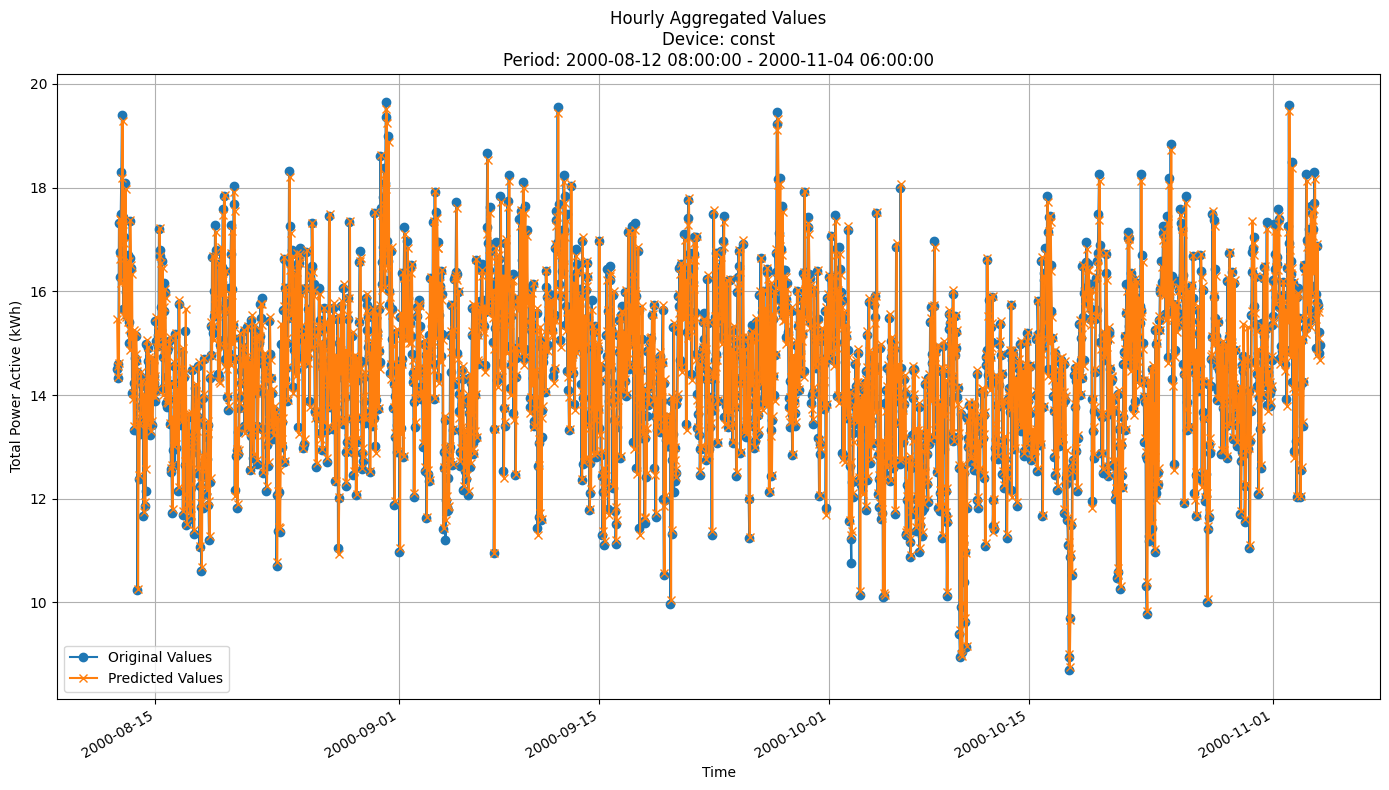


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5226
MAE: 1.2055
MAPE: 8.5013%

Directional Metrics:
Directional Accuracy: 35.8313%
First-Diff Correlation: -0.4259

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [29]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {'n_models': 40, 
                 'max_features': 0.1, 
                 'max_depth': 7, 
                 'aggregation_method': 'median', 
                 'disable_weighted_vote': True, 
                 'drift_detector': None, 
                 'warning_detector': None, 
                 'tau': 0.005, 
                 'delta': 0.01, 
                 'grace_period': 96}


In [31]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00
Model's memory usage: 5.448418 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5217
	MAE: 1.2134
	MAPE: 8.5770%

Directional Metrics:
	Directional Accuracy: 38.0030%
	First-Diff Correlation: -0.3921

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 1.0000
		F1: 0.8000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00
Model's memory usage: 6.955879 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6340
	MAE: 1.3283
	MAPE: 8.9806%

Directional Metrics:
	Directional Accuracy: 36.6617%
	First-Diff Correlation: -0.4393

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00
Model's memory usage: 9.099182 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5615
	MAE: 1.2444
	MAPE: 8.7205%

Directional Metrics:
	Directional Accuracy: 34.2772%
	First-Diff Correlation: -0.4284

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00
Model's memory usage: 9.000908 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5034
	MAE: 1.1920
	MAPE: 8.5477%

Directional Metrics:
	Directional Accuracy: 35.3204%
	First-Diff Correlation: -0.4160

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 1.0000
		F1: 0.8571
	Drops:
		Precision: 0.8000
		Recall: 1.0000
		F1: 0.8889
--------------------------------------------------
Dai

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5474 ± 0.0144
	MAE: 1.2326 ± 0.0109
	MAPE: 8.6112% ± 0.1365%

	Directional Metrics:
		Directional Accuracy: 37.4291% ± 0.7965%
		First-Diff Correlation: -0.3986 ± 0.0197

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0037 ± 0.0111
		Drop Recall: 0.0036 ± 0.0107
		Drop F1: 0.0036 ± 0.0109

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9146 ± 0.1458
		Spike Recall: 0.9735 ± 0.0415
		Spike F1: 0.9345 ± 0.0940
		Drop Precision: 0.9488 ± 0.0795
		Drop Recall: 0.9774 ± 0.0345
		Drop F1: 0.9603 ± 0.0425
Daily Metrics:
	RMSE: 2.4472 ± 0.1683
	MAE: 1.9800 ± 0.1844
	MAPE: 0.5865% ± 0.0817%

	Directional Metrics:
		Directional Accuracy: 95.2973% ± 1.4652%
		First-Diff Correlation: 0.9940 ± 0.0012

	Immediate Detection (delta=0):
		Spik

#### Training plots

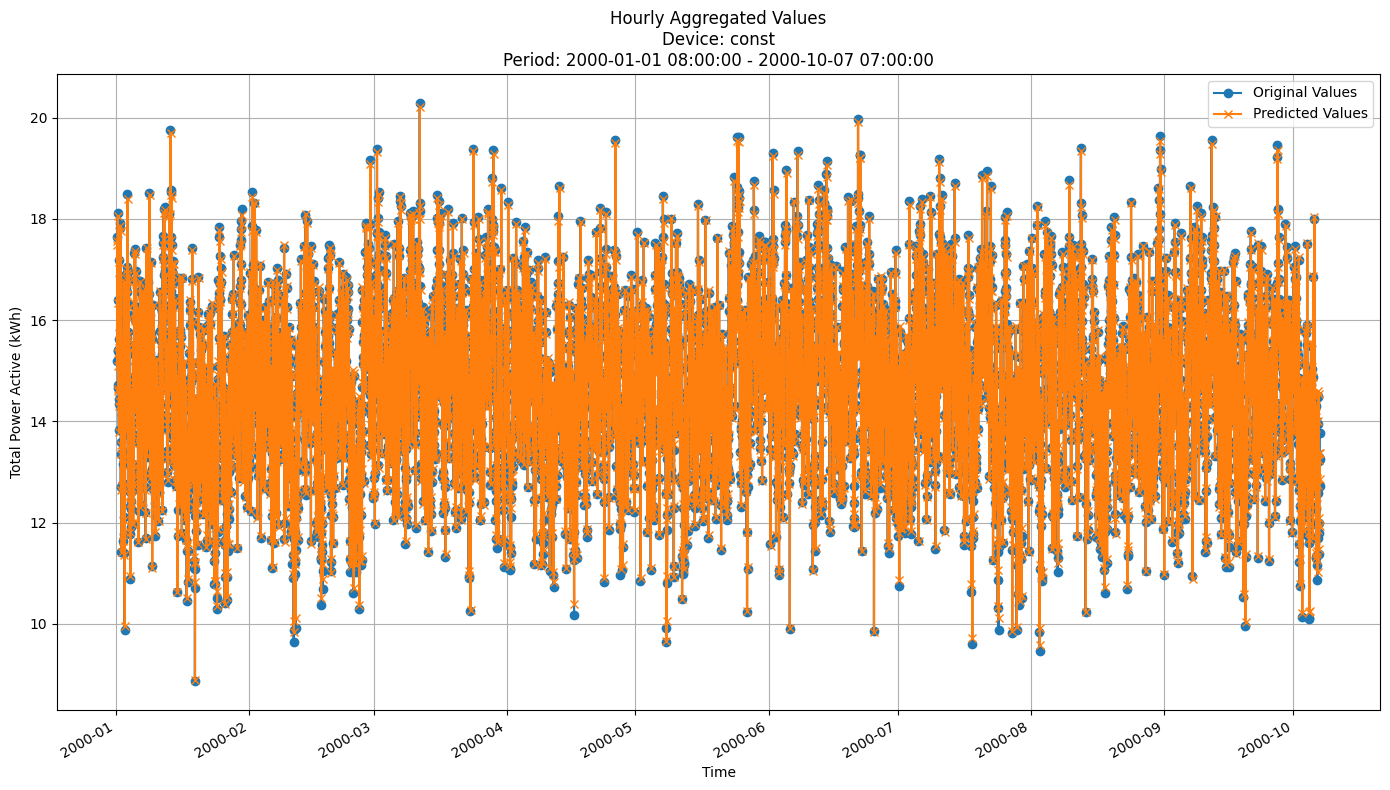


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5362
MAE: 1.2257
MAPE: 8.5086%

Directional Metrics:
Directional Accuracy: 36.4841%
First-Diff Correlation: -0.4167

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

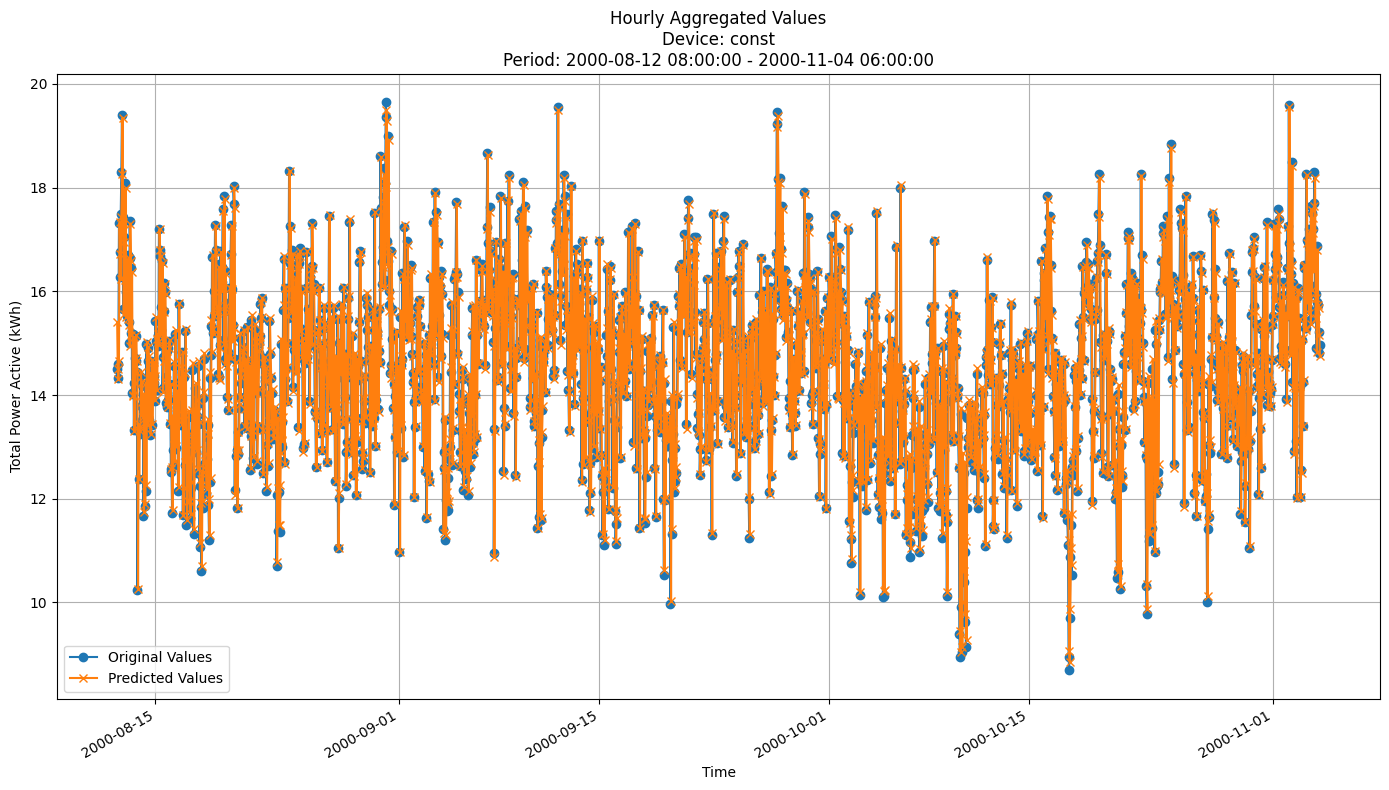


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5222
MAE: 1.2062
MAPE: 8.5058%

Directional Metrics:
Directional Accuracy: 35.0372%
First-Diff Correlation: -0.4307

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [34]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [35]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 50, 
               'grace_period': 0, 
               'grace_period_depth': 1, 
               'split_confidence': 0.005, 
               'max_feature': 0.3, 
               'tie_threshold': 0.01, 
               'bin_type': 'adaptive', 
               'max_bins': 8, 
               'split_criterion': 'vr_rel'}

In [36]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00
Model's memory usage: 0.011032 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5177
	MAE: 1.2086
	MAPE: 8.5383%

Directional Metrics:
	Directional Accuracy: 38.7481%
	First-Diff Correlation: -0.3979

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 1.0000
		F1: 0.8000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00
Model's memory usage: 0.009438 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6355
	MAE: 1.3303
	MAPE: 8.9980%

Directional Metrics:
	Directional Accuracy: 36.2146%
	First-Diff Correlation: -0.4446

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00
Model's memory usage: 0.009109 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5635
	MAE: 1.2471
	MAPE: 8.7381%

Directional Metrics:
	Directional Accuracy: 34.1282%
	First-Diff Correlation: -0.4322

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00
Model's memory usage: 0.010712 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5052
	MAE: 1.1936
	MAPE: 8.5506%

Directional Metrics:
	Directional Accuracy: 35.7675%
	First-Diff Correlation: -0.4187

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

#### Results

In [37]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5573 ± 0.0178
	MAE: 1.2409 ± 0.0130
	MAPE: 8.6690% ± 0.1562%

	Directional Metrics:
		Directional Accuracy: 37.4494% ± 0.8119%
		First-Diff Correlation: -0.4060 ± 0.0179

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9933 ± 0.0136
		Spike F1: 0.9966 ± 0.0069
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 0.9935 ± 0.0131
		Drop F1: 0.9967 ± 0.0067
Daily Metrics:
	RMSE: 2.3943 ± 0.2206
	MAE: 1.9049 ± 0.2497
	MAPE: 0.5639% ± 0.1016%

	Directional Metrics:
		Directional Accuracy: 94.9060% ± 1.6098%
		First-Diff Correlation: 0.9936 ± 0.0013

	Immediate Detection (delta=0):
		Spik

#### Training plots


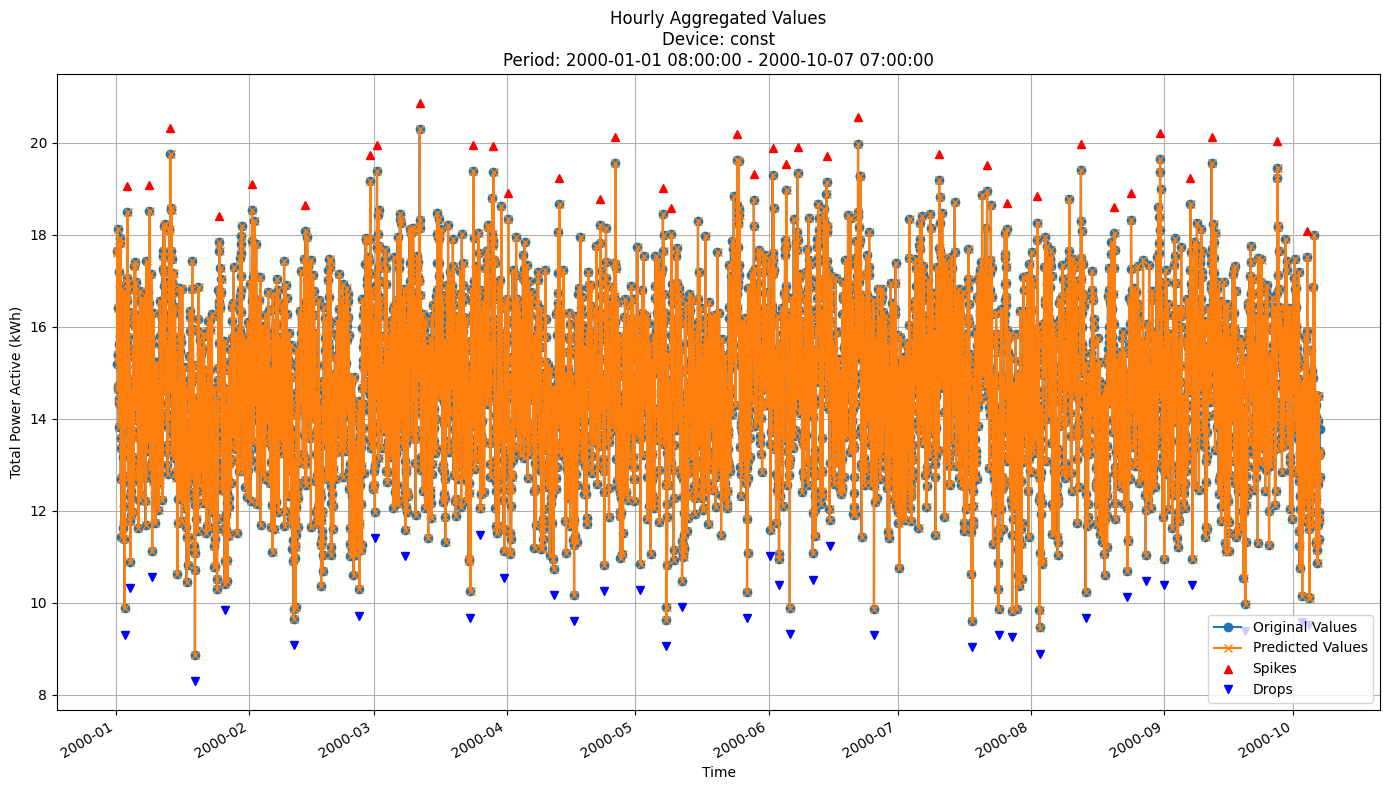


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5421
MAE: 1.2312
MAPE: 8.5462%

Directional Metrics:
Directional Accuracy: 36.5287%
First-Diff Correlation: -0.4215

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [38]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

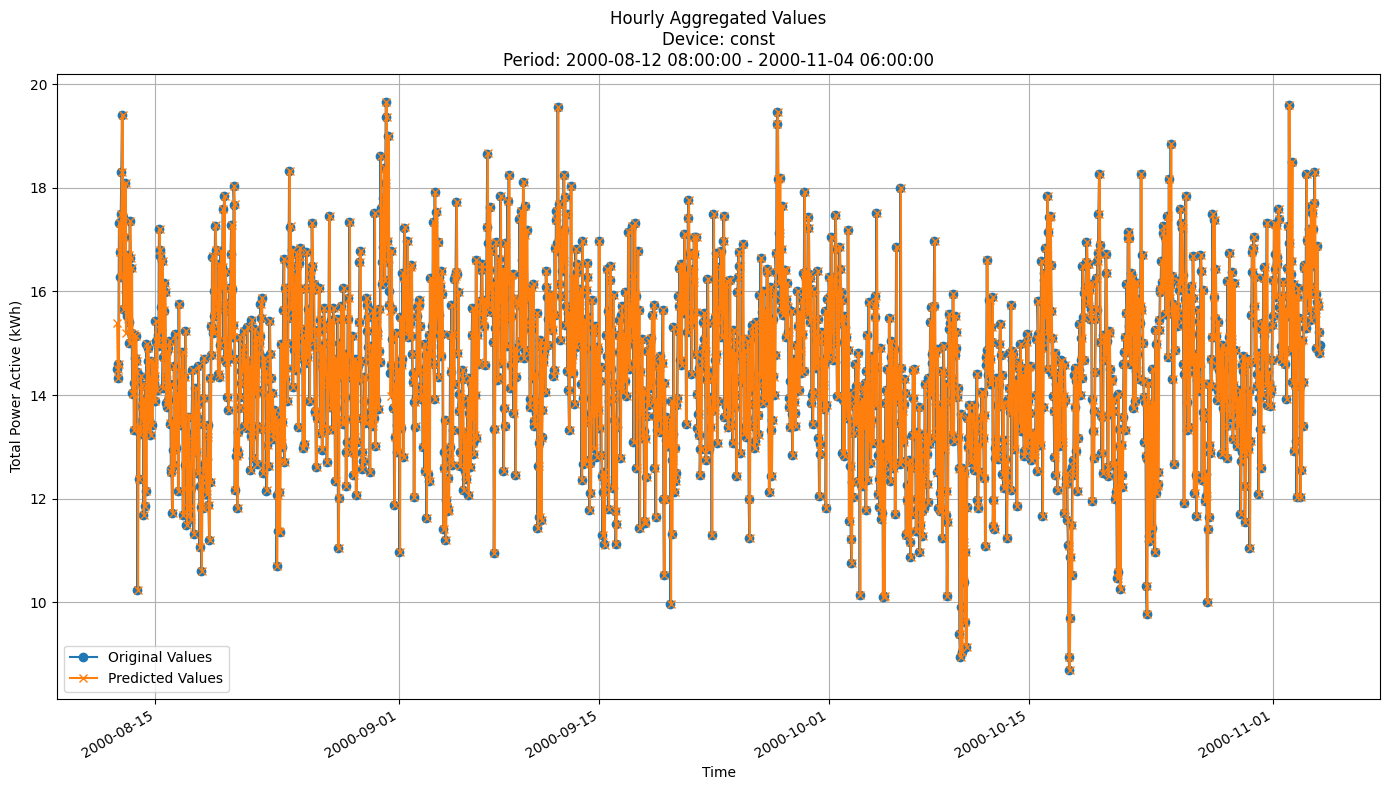


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5237
MAE: 1.2081
MAPE: 8.5149%

Directional Metrics:
Directional Accuracy: 35.1861%
First-Diff Correlation: -0.4333

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [40]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = {'n_models': 30, 
              'max_features': 0.7, 
              'max_depth': 10, 
              'aggregation_method': 'mean', 
              'disable_weighted_vote': False, 
              'drift_detector': None, 
              'warning_detector': None, 
              'eagerness': 0, 'tau': 0.05, 
              'delta': 0.5, 
              'grace_period': 96, 
              'grace_period_depth': 1, 
              'bin_type': 'mean', 
              'split_criterion': 'vr_rel'}


In [41]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00
Model's memory usage: 4.875008 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5166
	MAE: 1.2080
	MAPE: 8.5351%

Directional Metrics:
	Directional Accuracy: 38.4501%
	First-Diff Correlation: -0.3976

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 1.0000
		F1: 0.8000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00
Model's memory usage: 4.890038 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6349
	MAE: 1.3294
	MAPE: 8.9919%

Directional Metrics:
	Directional Accuracy: 36.2146%
	First-Diff Correlation: -0.4435

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00
Model's memory usage: 4.822388 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5636
	MAE: 1.2468
	MAPE: 8.7360%

Directional Metrics:
	Directional Accuracy: 34.1282%
	First-Diff Correlation: -0.4316

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00
Model's memory usage: 4.867676 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5046
	MAE: 1.1932
	MAPE: 8.5479%

Directional Metrics:
	Directional Accuracy: 35.6185%
	First-Diff Correlation: -0.4189

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 1.0000
		F1: 0.8571
	Drops:
		Precision: 0.8000
		Recall: 1.0000
		F1: 0.8889
--------------------------------------------------
Dai

#### Results

In [42]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5570 ± 0.0176
	MAE: 1.2405 ± 0.0127
	MAPE: 8.6667% ± 0.1543%

	Directional Metrics:
		Directional Accuracy: 37.3685% ± 0.8139%
		First-Diff Correlation: -0.4056 ± 0.0180

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9612 ± 0.0494
		Spike Recall: 1.0000 ± 0.0000
		Spike F1: 0.9796 ± 0.0264
		Drop Precision: 0.9669 ± 0.0458
		Drop Recall: 1.0000 ± 0.0000
		Drop F1: 0.9826 ± 0.0242
Daily Metrics:
	RMSE: 2.4105 ± 0.2174
	MAE: 1.9110 ± 0.2369
	MAPE: 0.5659% ± 0.0984%

	Directional Metrics:
		Directional Accuracy: 94.9060% ± 1.6098%
		First-Diff Correlation: 0.9935 ± 0.0013

	Immediate Detection (delta=0):
		Spik

#### Training plots

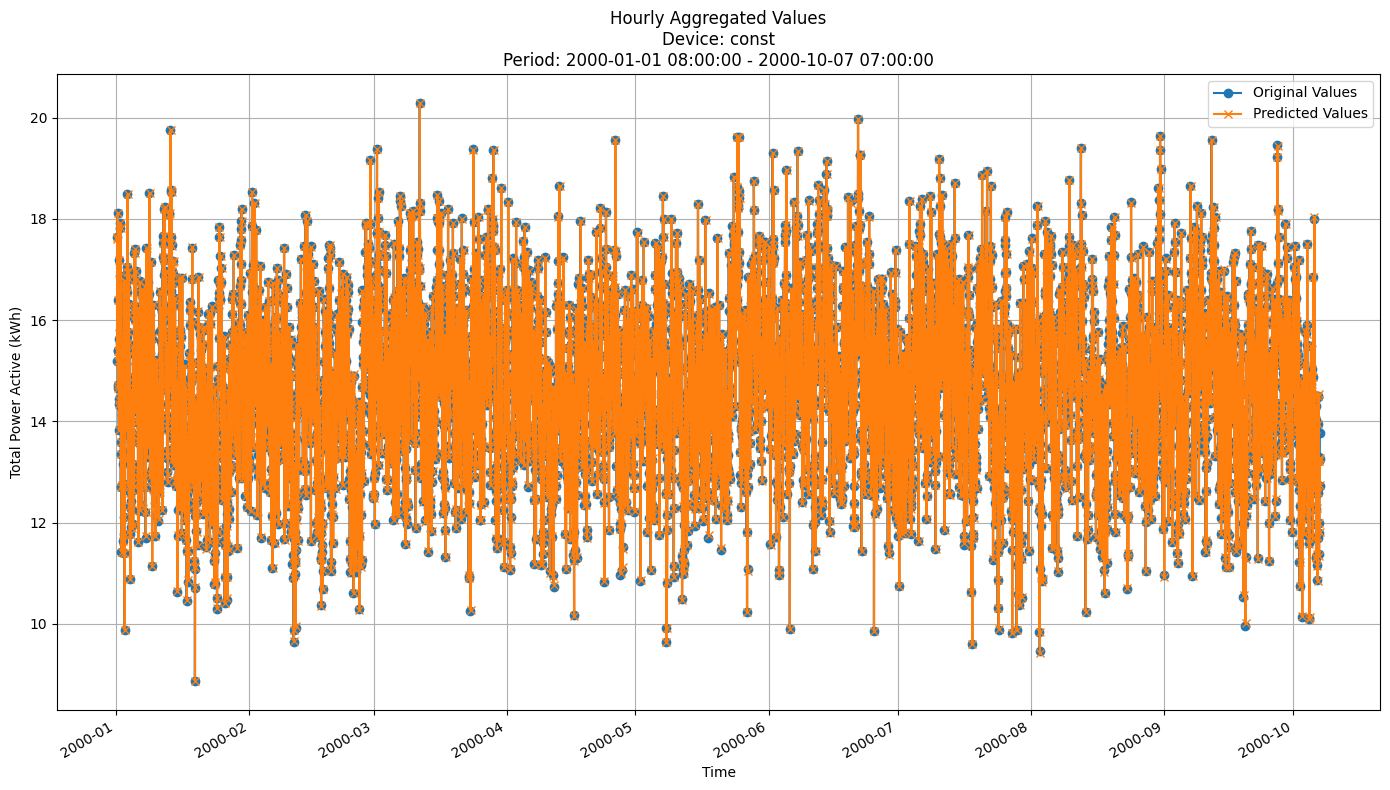


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5420
MAE: 1.2310
MAPE: 8.5452%

Directional Metrics:
Directional Accuracy: 36.4841%
First-Diff Correlation: -0.4211

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [43]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

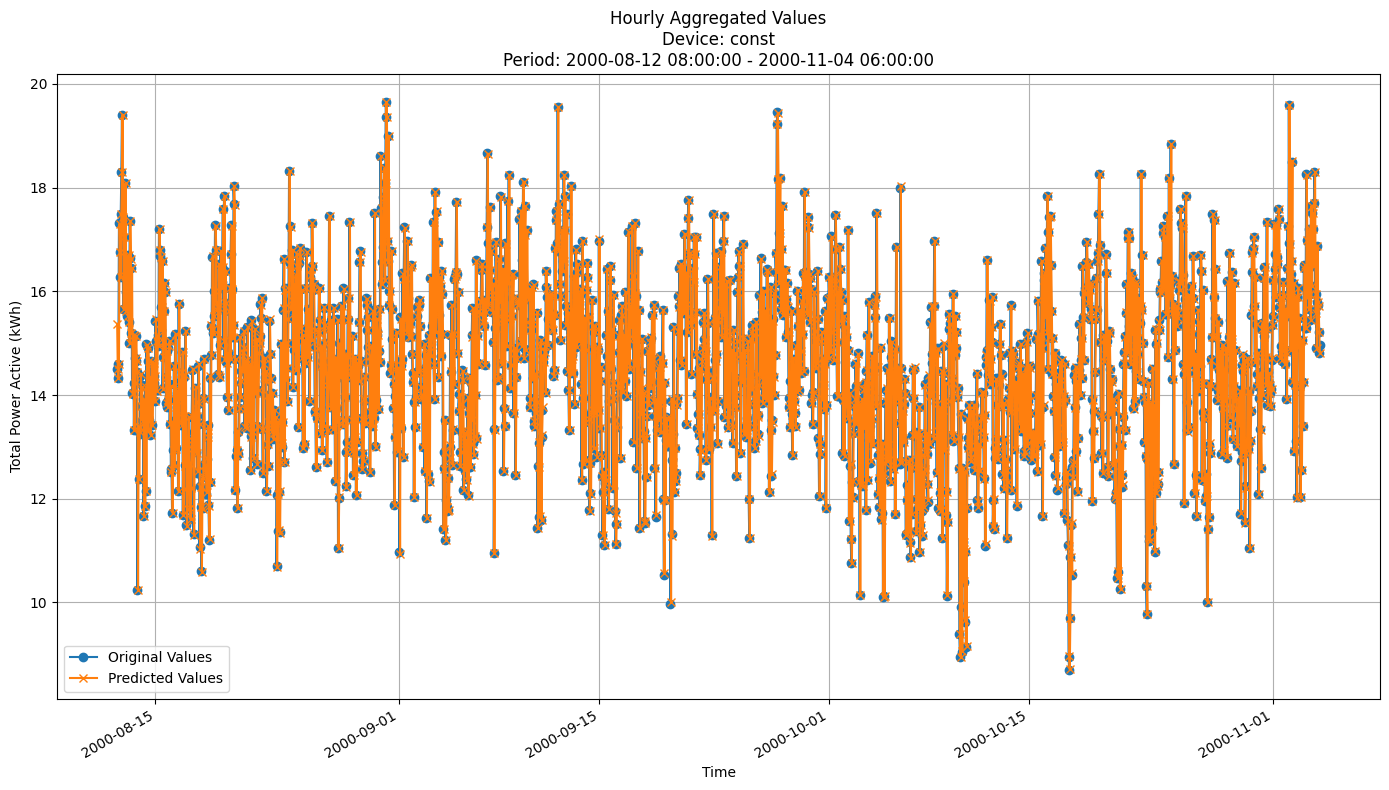


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5236
MAE: 1.2076
MAPE: 8.5115%

Directional Metrics:
Directional Accuracy: 35.0868%
First-Diff Correlation: -0.4335

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [44]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [45]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

incb = IncubationBoost
incb_params = {'length': 5, 
               'learning_rate': 0.001, 
               'depth': 20, 
               'grace_period': 0, 
               'grace_period_depth': -1, 
               'split_confidence': 0.01, 
               'max_feature': 1.0, 
               'tie_threshold': 0.01, 
               'bin_type': 'adaptive', 
               'max_bins': 32, 
               'split_criterion': 'vr_rel', 
               'verbose': False}

In [46]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00
Model's memory usage: 0.073563 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5177
	MAE: 1.2084
	MAPE: 8.5385%

Directional Metrics:
	Directional Accuracy: 38.7481%
	First-Diff Correlation: -0.3979

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 1.0000
		F1: 0.8000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00
Model's memory usage: 0.077515 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6355
	MAE: 1.3303
	MAPE: 8.9987%

Directional Metrics:
	Directional Accuracy: 36.2146%
	First-Diff Correlation: -0.4446

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00
Model's memory usage: 0.084106 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5635
	MAE: 1.2471
	MAPE: 8.7382%

Directional Metrics:
	Directional Accuracy: 34.1282%
	First-Diff Correlation: -0.4322

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00
Model's memory usage: 0.088455 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5052
	MAE: 1.1936
	MAPE: 8.5507%

Directional Metrics:
	Directional Accuracy: 35.7675%
	First-Diff Correlation: -0.4187

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

#### Results

In [47]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5573 ± 0.0178
	MAE: 1.2409 ± 0.0130
	MAPE: 8.6694% ± 0.1563%

	Directional Metrics:
		Directional Accuracy: 37.4494% ± 0.8119%
		First-Diff Correlation: -0.4060 ± 0.0179

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9933 ± 0.0136
		Spike F1: 0.9966 ± 0.0069
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 0.9935 ± 0.0131
		Drop F1: 0.9967 ± 0.0067
Daily Metrics:
	RMSE: 2.3968 ± 0.2178
	MAE: 1.9033 ± 0.2425
	MAPE: 0.5637% ± 0.0999%

	Directional Metrics:
		Directional Accuracy: 94.9060% ± 1.6098%
		First-Diff Correlation: 0.9936 ± 0.0013

	Immediate Detection (delta=0):
		Spik

#### Train plots

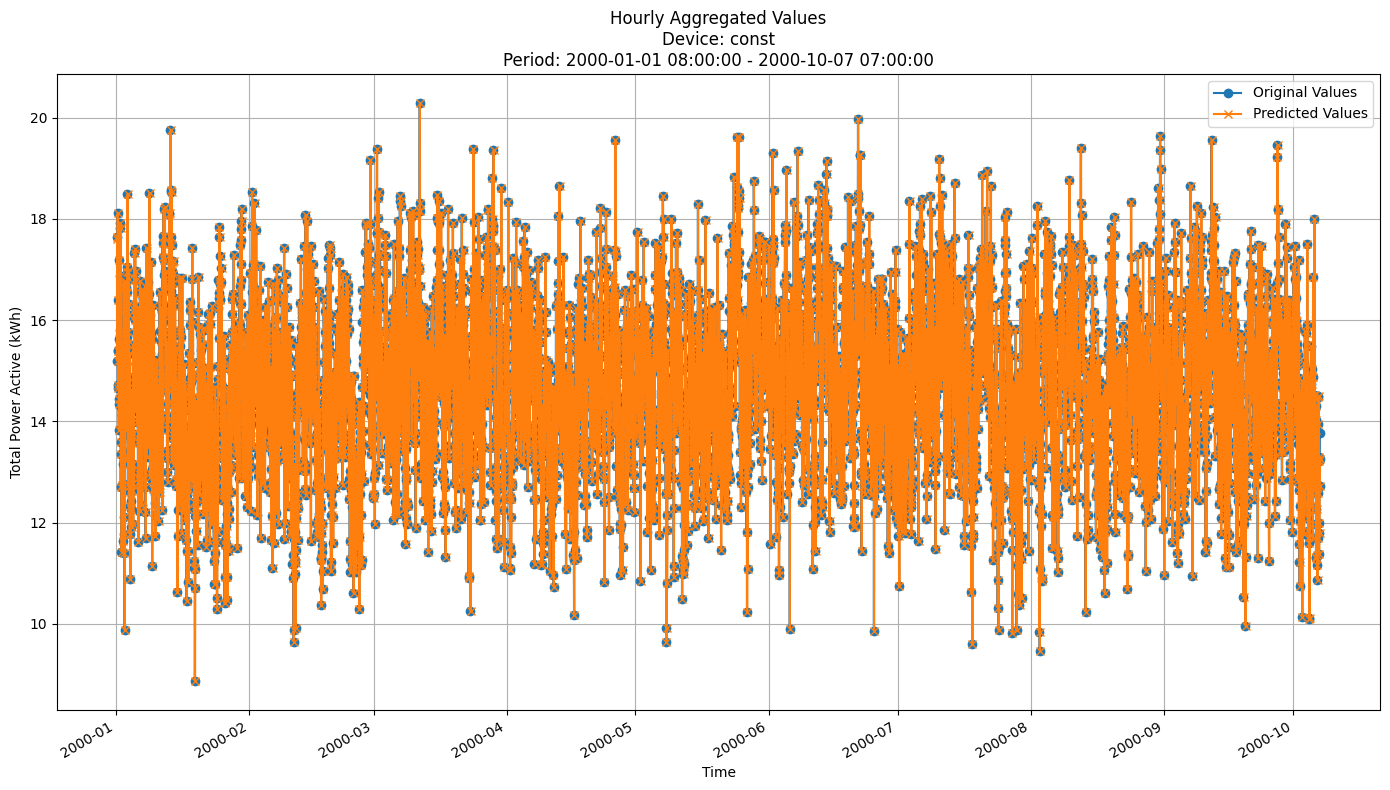


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5421
MAE: 1.2311
MAPE: 8.5463%

Directional Metrics:
Directional Accuracy: 36.5287%
First-Diff Correlation: -0.4215

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [48]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

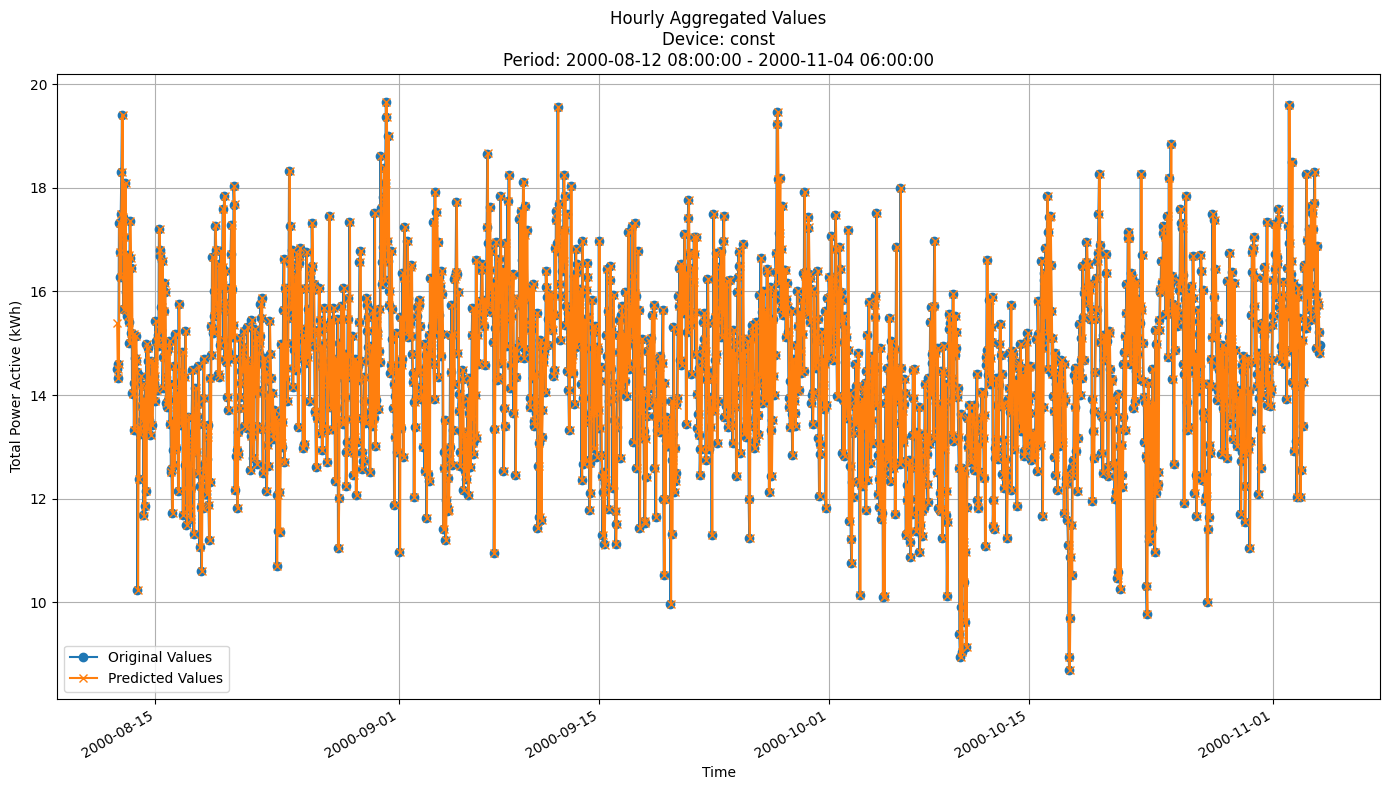


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5238
MAE: 1.2078
MAPE: 8.5135%

Directional Metrics:
Directional Accuracy: 35.1365%
First-Diff Correlation: -0.4338

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [49]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

## iNcubation Boost (elastic pruning)

In [50]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

elastic = IncubationBoostElastic
elastic_params = {'length': 5, 
               'learning_rate': 0.001, 
               'depth': 20, 
               'grace_period': 0, 
               'grace_period_depth': -1, 
               'split_confidence': 0.01, 
               'max_feature': 1.0, 
               'tie_threshold': 0.01, 
               'bin_type': 'adaptive', 
               'max_bins': 32, 
               'split_criterion': 'vr_rel', 
               'verbose': False}

In [51]:
elastic_all_train_preds, elastic_all_valid_preds, \
elastic_all_train_metrics, elastic_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=elastic, 
    model_params=elastic_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1)

Processing splits:   0%|          | 0/10 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-01-29 06:00:00+01:00
Model's memory usage: 0.073563 MB
Metrics for Device: const | Period: 2000-01-29 07:00:00+01:00 - 2000-02-26 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5177
	MAE: 1.2084
	MAPE: 8.5385%

Directional Metrics:
	Directional Accuracy: 38.7481%
	First-Diff Correlation: -0.3979

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 1.0000
		F1: 0.8000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-02-26 06:00:00+01:00
Model's memory usage: 0.077515 MB
Metrics for Device: const | Period: 2000-02-26 07:00:00+01:00 - 2000-03-25 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6355
	MAE: 1.3303
	MAPE: 8.9987%

Directional Metrics:
	Directional Accuracy: 36.2146%
	First-Diff Correlation: -0.4446

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices in split 8:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-09-09 07:00:00+02:00
Model's memory usage: 0.084106 MB
Metrics for Device: const | Period: 2000-09-09 08:00:00+02:00 - 2000-10-07 07:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5635
	MAE: 1.2471
	MAPE: 8.7382%

Directional Metrics:
	Directional Accuracy: 34.1282%
	First-Diff Correlation: -0.4322

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 9:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-10-07 07:00:00+02:00
Model's memory usage: 0.088455 MB
Metrics for Device: const | Period: 2000-10-07 08:00:00+02:00 - 2000-11-04 06:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5052
	MAE: 1.1936
	MAPE: 8.5507%

Directional Metrics:
	Directional Accuracy: 35.7675%
	First-Diff Correlation: -0.4187

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

### Results

In [52]:
print("\n\nTrain period metrics:")
elastic_all_time_train_metrics = all_time_aggregation_metrics(elastic_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
elastic_all_time_valid_metrics = all_time_aggregation_metrics(elastic_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.5573 ± 0.0178
	MAE: 1.2409 ± 0.0130
	MAPE: 8.6694% ± 0.1563%

	Directional Metrics:
		Directional Accuracy: 37.4494% ± 0.8119%
		First-Diff Correlation: -0.4060 ± 0.0179

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9933 ± 0.0136
		Spike F1: 0.9966 ± 0.0069
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 0.9935 ± 0.0131
		Drop F1: 0.9967 ± 0.0067
Daily Metrics:
	RMSE: 2.3968 ± 0.2178
	MAE: 1.9033 ± 0.2425
	MAPE: 0.5637% ± 0.0999%

	Directional Metrics:
		Directional Accuracy: 94.9060% ± 1.6098%
		First-Diff Correlation: 0.9936 ± 0.0013

	Immediate Detection (delta=0):
		Spik

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [53]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb, elastic]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
    elastic_params
]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-11-04 06:00:00+01:00
Model's memory usage: 0.000435 MB
Metrics for Device: const | Period: 2000-11-29 09:00:00+01:00 - 2001-02-20 14:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5160
	MAE: 1.2060
	MAPE: 8.3434%

Directional Metrics:
	Directional Accuracy: 35.3530%
	First-Diff Correlation: -0.4467

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9000
		Recall: 1.0000
		F1: 0.9474
	Drops:
		Precision: 0.9091
		Recall: 1.0000
		F1: 0.9524
--------------------------------------------------
Dai

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-11-04 06:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2000-11-29 09:00:00+01:00 to 2000-12-13 09:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-12-13 09:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2000-12-13 10:00:00+01:00 to 2000-12-27 10:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2000-12-27 10:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2000-12-27 11:00:00+01:00 to 2001-01-10 11:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2001-01-10 11:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2001-01-10 12:00:00+01:00 to 2001-01-24 12:00:00+01:00

-------------------------

Retraining model on data from 2000-01-01 08:00:00+01:00 to 2001-01-24 12:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2001-01-24 1

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-11-04 06:00:00+01:00
Model's memory usage: 0.092285 MB
Metrics for Device: const | Period: 2000-11-29 09:00:00+01:00 - 2001-02-20 14:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5161
	MAE: 1.2061
	MAPE: 8.3439%

Directional Metrics:
	Directional Accuracy: 35.3530%
	First-Diff Correlation: -0.4467

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9000
		Recall: 1.0000
		F1: 0.9474
	Drops:
		Precision: 0.9091
		Recall: 1.0000
		F1: 0.9524
--------------------------------------------------
Dai

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 9
Filtered feature count: 9
Excluded lag features: None
Initial training on data from 2000-01-01 08:00:00+01:00 to 2000-11-04 06:00:00+01:00
Model's memory usage: 0.092285 MB
Metrics for Device: const | Period: 2000-11-29 09:00:00+01:00 - 2001-02-20 14:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.5161
	MAE: 1.2061
	MAPE: 8.3439%

Directional Metrics:
	Directional Accuracy: 35.3530%
	First-Diff Correlation: -0.4467

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9000
		Recall: 1.0000
		F1: 0.9474
	Drops:
		Precision: 0.9091
		Recall: 1.0000
		F1: 0.9524
--------------------------------------------------
Dai

In [54]:
for model_class in models_classes:
    model_test_results[model_class.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model_class.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [55]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [56]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
    "IncubationBoostElastic": model_test_results[elastic.__name__]["test_metrics"],
}

In [57]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [58]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: const | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.516 ± 0.000,1.206 ± 0.000,8.343 ± 0.000,35.353 ± 0.000,-44.665 ± 0.000,0.000 ± 0.000,94.737 ± 0.000,0.000 ± 0.000,95.238 ± 0.000
1,BL_Mean,1.528 ± 0.000,1.219 ± 0.000,8.429 ± 0.000,35.653 ± 0.000,-43.509 ± 0.000,0.000 ± 0.000,77.778 ± 0.000,0.000 ± 0.000,80.000 ± 0.000
2,GBDT,1.515 ± 0.000,1.205 ± 0.000,8.339 ± 0.000,35.603 ± 0.000,-44.027 ± 0.000,0.000 ± 0.000,84.211 ± 0.000,0.000 ± 0.000,95.238 ± 0.000
3,RandomForest,1.513 ± 0.000,1.204 ± 0.000,8.330 ± 0.000,35.453 ± 0.000,-44.312 ± 0.000,0.000 ± 0.000,76.190 ± 0.000,0.000 ± 0.000,86.957 ± 0.000
4,HoeffdingTree,1.515 ± 0.000,1.204 ± 0.000,8.331 ± 0.000,35.553 ± 0.000,-43.907 ± 0.000,0.000 ± 0.000,94.737 ± 0.000,0.000 ± 0.000,95.238 ± 0.000
5,ARF_Hoeffding,1.514 ± 0.000,1.205 ± 0.000,8.337 ± 0.000,35.303 ± 0.000,-44.376 ± 0.000,0.000 ± 0.000,90.000 ± 0.000,0.000 ± 0.000,90.909 ± 0.000
6,FastODT,1.516 ± 0.000,1.206 ± 0.000,8.344 ± 0.000,35.353 ± 0.000,-44.665 ± 0.000,0.000 ± 0.000,94.737 ± 0.000,0.000 ± 0.000,95.238 ± 0.000
7,ARF_FastODT,1.516 ± 0.000,1.206 ± 0.000,8.341 ± 0.000,35.403 ± 0.000,-44.617 ± 0.000,0.000 ± 0.000,94.737 ± 0.000,0.000 ± 0.000,85.714 ± 0.000
8,IncubationBoost,1.516 ± 0.000,1.206 ± 0.000,8.344 ± 0.000,35.353 ± 0.000,-44.665 ± 0.000,0.000 ± 0.000,94.737 ± 0.000,0.000 ± 0.000,95.238 ± 0.000
9,IncubationBoostElastic,1.516 ± 0.000,1.206 ± 0.000,8.344 ± 0.000,35.353 ± 0.000,-44.665 ± 0.000,0.000 ± 0.000,94.737 ± 0.000,0.000 ± 0.000,95.238 ± 0.000


## Validation results

In [59]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
    "IncubationBoostElastic": elastic_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: const | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.532 ± 0.055,1.225 ± 0.054,8.501 ± 0.301,36.230 ± 1.908,-42.559 ± 3.601,0.000 ± 0.000,98.000 ± 6.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,1.581 ± 0.069,1.265 ± 0.063,8.778 ± 0.372,36.870 ± 2.387,-39.744 ± 4.330,0.000 ± 0.000,62.738 ± 20.238,2.000 ± 6.000,69.389 ± 22.436
2,GBDT,1.533 ± 0.057,1.225 ± 0.055,8.501 ± 0.306,36.468 ± 1.712,-41.391 ± 3.700,2.857 ± 8.571,82.048 ± 15.848,0.000 ± 0.000,84.905 ± 17.457
3,RandomForest,1.532 ± 0.011,1.222 ± 0.012,8.536 ± 0.084,37.842 ± 1.235,-38.621 ± 3.067,0.000 ± 0.000,89.751 ± 17.286,2.917 ± 5.066,93.946 ± 9.448
4,HoeffdingTree,1.534 ± 0.055,1.225 ± 0.053,8.503 ± 0.300,36.811 ± 2.039,-41.540 ± 3.643,0.000 ± 0.000,90.143 ± 10.424,5.000 ± 15.000,83.889 ± 18.333
5,ARF_Hoeffding,1.532 ± 0.055,1.224 ± 0.055,8.498 ± 0.303,36.110 ± 1.716,-42.225 ± 3.573,0.000 ± 0.000,94.071 ± 9.368,0.000 ± 0.000,94.889 ± 8.138
6,FastODT,1.533 ± 0.055,1.225 ± 0.054,8.503 ± 0.301,36.244 ± 1.904,-42.543 ± 3.590,0.000 ± 0.000,98.000 ± 6.000,0.000 ± 0.000,100.000 ± 0.000
7,ARF_FastODT,1.532 ± 0.055,1.225 ± 0.054,8.500 ± 0.301,36.185 ± 1.897,-42.525 ± 3.595,0.000 ± 0.000,96.571 ± 6.975,0.000 ± 0.000,96.889 ± 6.532
8,IncubationBoost,1.533 ± 0.055,1.225 ± 0.054,8.502 ± 0.301,36.230 ± 1.908,-42.559 ± 3.601,0.000 ± 0.000,98.000 ± 6.000,0.000 ± 0.000,100.000 ± 0.000
9,IncubationBoostElastic,1.533 ± 0.055,1.225 ± 0.054,8.502 ± 0.301,36.230 ± 1.908,-42.559 ± 3.601,0.000 ± 0.000,98.000 ± 6.000,0.000 ± 0.000,100.000 ± 0.000


### By-period validation results

In [60]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Mean": bl_prev_valid_period_metrics,
    "BL_Prev": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [61]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: const | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,38.748,41.133,37.258,38.450,39.493,38.003,38.748,38.450,38.748,38.781222
Period 2,36.215,35.618,37.556,37.705,37.109,36.662,36.215,36.215,36.215,36.612222
Period 3,33.234,34.724,33.979,33.234,33.383,33.532,33.234,33.085,33.234,33.515444
Period 4,40.089,41.580,40.238,40.238,40.984,39.642,40.089,40.089,40.089,40.337556
Period 5,36.811,35.768,37.556,37.258,37.258,37.109,36.811,36.960,36.811,36.926889
Period 6,35.320,35.469,35.469,35.768,36.215,35.022,35.320,35.469,35.320,35.485778
Period 7,36.364,37.407,35.469,35.320,36.066,35.917,36.364,36.215,36.364,36.165111
Period 8,35.618,35.320,35.917,35.469,35.320,35.618,35.768,35.618,35.618,35.585111
Period 9,34.128,34.724,34.575,34.277,35.469,34.277,34.128,34.128,34.128,34.426000
Period 10,35.768,36.960,36.662,35.618,36.811,35.320,35.768,35.618,35.768,36.032556



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-2.533,-5.515,0.298,-0.745,-2.384,-1.341,-2.533,-2.235,-2.533,-2.169
Period 3 - Period 2,-2.981,-0.894,-3.577,-4.471,-3.726,-3.130,-2.981,-3.130,-2.981,-3.097
Period 4 - Period 3,6.855,6.856,6.259,7.004,7.601,6.110,6.855,7.004,6.855,6.822
Period 5 - Period 4,-3.278,-5.812,-2.682,-2.980,-3.726,-2.533,-3.278,-3.129,-3.278,-3.411
Period 6 - Period 5,-1.491,-0.299,-2.087,-1.490,-1.043,-2.087,-1.491,-1.491,-1.491,-1.441
Period 7 - Period 6,1.044,1.938,0.000,-0.448,-0.149,0.895,1.044,0.746,1.044,0.679
Period 8 - Period 7,-0.746,-2.087,0.448,0.149,-0.746,-0.299,-0.596,-0.597,-0.746,-0.580
Period 9 - Period 8,-1.490,-0.596,-1.342,-1.192,0.149,-1.341,-1.640,-1.490,-1.490,-1.159
Period 10 - Period 9,1.640,2.236,2.087,1.341,1.342,1.043,1.640,1.490,1.640,1.607


#### MAPE (lower is better)

In [62]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: const | Aggregation: hourly | MAPE (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,8.535,9.240,8.528,8.534,8.657,8.577,8.538,8.535,8.539,8.631444
Period 2,8.996,9.400,8.997,8.973,8.933,8.981,8.998,8.992,8.999,9.029889
Period 3,8.485,8.879,8.514,8.494,8.503,8.490,8.486,8.489,8.487,8.536333
Period 4,7.814,8.038,7.787,7.762,7.786,7.792,7.815,7.811,7.816,7.824556
Period 5,8.437,8.711,8.441,8.439,8.448,8.439,8.438,8.437,8.438,8.469778
Period 6,8.746,8.833,8.744,8.724,8.734,8.738,8.747,8.749,8.747,8.751333
Period 7,8.456,8.759,8.470,8.454,8.467,8.448,8.457,8.454,8.457,8.491333
Period 8,8.251,8.359,8.255,8.245,8.234,8.249,8.256,8.251,8.252,8.261333
Period 9,8.737,8.930,8.729,8.720,8.702,8.721,8.738,8.736,8.738,8.750111
Period 10,8.550,8.636,8.546,8.537,8.568,8.548,8.551,8.548,8.551,8.559444



Absolute gain/drop in MAPE (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.461,0.160,0.469,0.439,0.276,0.404,0.460,0.457,0.460,0.398
Period 3 - Period 2,-0.511,-0.521,-0.483,-0.479,-0.430,-0.491,-0.512,-0.503,-0.512,-0.494
Period 4 - Period 3,-0.671,-0.841,-0.727,-0.732,-0.717,-0.698,-0.671,-0.678,-0.671,-0.712
Period 5 - Period 4,0.623,0.673,0.654,0.677,0.662,0.647,0.623,0.626,0.622,0.645
Period 6 - Period 5,0.309,0.122,0.303,0.285,0.286,0.299,0.309,0.312,0.309,0.282
Period 7 - Period 6,-0.290,-0.074,-0.274,-0.270,-0.267,-0.290,-0.290,-0.295,-0.290,-0.260
Period 8 - Period 7,-0.205,-0.400,-0.215,-0.209,-0.233,-0.199,-0.201,-0.203,-0.205,-0.230
Period 9 - Period 8,0.486,0.571,0.474,0.475,0.468,0.472,0.482,0.485,0.486,0.489
Period 10 - Period 9,-0.187,-0.294,-0.183,-0.183,-0.134,-0.173,-0.187,-0.188,-0.187,-0.191


#### RMSE (lower is better)

In [63]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: const | Aggregation: hourly | RMSE per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.517,1.659,1.510,1.508,1.526,1.522,1.518,1.517,1.518,1.532778
Period 2,1.635,1.716,1.645,1.640,1.636,1.634,1.636,1.635,1.636,1.645889
Period 3,1.548,1.601,1.550,1.547,1.552,1.549,1.548,1.548,1.548,1.554556
Period 4,1.419,1.465,1.418,1.413,1.419,1.416,1.419,1.418,1.419,1.422889
Period 5,1.570,1.616,1.572,1.570,1.576,1.571,1.570,1.569,1.570,1.576000
Period 6,1.564,1.574,1.564,1.561,1.561,1.563,1.564,1.564,1.564,1.564333
Period 7,1.502,1.542,1.503,1.501,1.503,1.500,1.502,1.501,1.502,1.506222
Period 8,1.502,1.524,1.502,1.500,1.500,1.501,1.502,1.502,1.502,1.503889
Period 9,1.563,1.591,1.563,1.561,1.562,1.562,1.564,1.564,1.564,1.566000
Period 10,1.505,1.520,1.506,1.501,1.505,1.503,1.505,1.505,1.505,1.506111



Absolute gain/drop in RMSE:


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.118,0.057,0.135,0.132,0.110,0.112,0.118,0.118,0.118,0.113
Period 3 - Period 2,-0.087,-0.115,-0.095,-0.093,-0.084,-0.085,-0.088,-0.087,-0.088,-0.091
Period 4 - Period 3,-0.129,-0.136,-0.132,-0.134,-0.133,-0.133,-0.129,-0.130,-0.129,-0.132
Period 5 - Period 4,0.151,0.151,0.154,0.157,0.157,0.155,0.151,0.151,0.151,0.153
Period 6 - Period 5,-0.006,-0.042,-0.008,-0.009,-0.015,-0.008,-0.006,-0.005,-0.006,-0.012
Period 7 - Period 6,-0.062,-0.032,-0.061,-0.060,-0.058,-0.063,-0.062,-0.063,-0.062,-0.058
Period 8 - Period 7,0.000,-0.018,-0.001,-0.001,-0.003,0.001,0.000,0.001,0.000,-0.002
Period 9 - Period 8,0.061,0.067,0.061,0.061,0.062,0.061,0.062,0.062,0.062,0.062
Period 10 - Period 9,-0.058,-0.071,-0.057,-0.060,-0.057,-0.059,-0.059,-0.059,-0.059,-0.060
